**Aim:** Identify cell types 

**Tools**: 
- [`scanpy`](https://scanpy.readthedocs.io/en/stable/)

<!-- ## cell typing email discussion  -->
<!-- 1) There might be a duplicate folder for the same acute female data. Please ignore the duplicate folder. And yes, I deleted the outs folder for this sample.  -->
<!-- 2) The cell counts look correct. Some are lower than others. I think for the initial analysis the MDMA male and acute male can be pooled. If necessary, you could normalize the data.  -->
<!-- 3) The tdTomato gene is annotated with Gt(ROSA)26Sor. The sequence (gene="Gt(ROSA)26Sor”) is from the Ai14 mouse line and is listed here: https://www.ncbi.nlm.nih.gov/nuccore/NR_027008  -->
<!-- Maybe it would be best to first divide the data into tdTomato+ and tdT- populations.  -->
<!-- 4) The Fos is relevant for the acute conditions, but we can focus on it later. -->
<!-- 5) I've attached the excel spreadsheet you sent with some genes labeled as potential markers.  -->
<!-- 6) I've attached a word doc with markers from papers I sent you previously. The one paper I haven't sent, I've attached here.  -->

In [1]:
import os, sys
import pickle
import numpy as np 
import pandas as pd
from glob import glob

import scanpy as sc
import scanpy.external as sce
import anndata as ad
import scvi

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import pyplot as plot
from matplotlib.backends.backend_pdf import PdfPages

sc.settings.verbosity = 1             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=300,dpi_save=300, frameon=False, figsize=(5, 5), facecolor='white')

sc.logging.print_header()

scanpy==1.9.1 anndata==0.7.6 umap==0.5.1 numpy==1.20.3 scipy==1.7.1 pandas==1.3.3 scikit-learn==1.0 statsmodels==0.13.0 python-igraph==0.9.8 pynndescent==0.5.4


In [2]:
# https://stackoverflow.com/questions/21884271/warning-about-too-many-open-figures
plt.rcParams.update({'figure.max_open_warning': 0})

plt.close('all')

In [3]:
# https://stackoverflow.com/questions/3899980/how-to-change-the-font-size-on-a-matplotlib-plot

SMALL_SIZE = 8
MEDIUM_SIZE = 10
BIGGER_SIZE = 12

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=SMALL_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title


In [4]:
from utils import *

Load preprocessed `adata`

In [5]:
results_file = 'preprocessing/adatas-merge-reps-clean.h5ad.gz'

adata = sc.read_h5ad(results_file)

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


In [6]:
adata.obs['group'] = adata.obs.cond.str.split('_').str[0]

In [7]:
adata.obs.groupby('group').size()

group
MDMA      10510
Meth       2990
Saline    10039
dtype: int64

In [8]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)

In [9]:
clustering(adata)

In [10]:
sc.pp.calculate_qc_metrics(adata,inplace=True)

In [11]:
adata.layers['scaled'] = sc.pp.scale(adata, copy=True).X

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


In [12]:
# pdf_pages = PdfPages(f'figures/violin_mitochondrial_{cond}.pdf')
# for col in [
#     'n_genes_by_counts','total_counts',
#     'pct_counts_mt'
# ]:
#     # Create a figure instance (ie. a new page)
#     fig = plot.figure(figsize=(12, 6), dpi=300)
#     # Plot whatever you wish to plot
#     print ('\033[1m' + col)
#     ax = plt.subplot()
#     sc.pl.violin(
#         adata, col, jitter=0.4, groupby='batch', 
#         multi_panel=True, ax=ax,rotation=90
#     )
#     # Done with the page
#     pdf_pages.savefig(fig,bbox_inches='tight')
# # Write the PDF document to the disk
# pdf_pages.close()

In [13]:
# writer = pd.ExcelWriter('cell-counts.xlsx', engine='xlsxwriter')
# # Write each dataframe to a different worksheet.
# pd.concat([
#     adata.obs.groupby('cond').size(),
#     adata_flt_mt.obs.groupby('cond').size(),
#     adata_flt_dd.obs.groupby('cond').size()
# ],axis=1).rename(columns={
#     0:'raw',1:'mt filtering',2:'doublet filtering'
# }).to_excel(writer,sheet_name='conditions')
# pd.concat([
#     adata.obs.groupby('batch').size(),
#     adata_flt_mt.obs.groupby('batch').size(),
#     adata_flt_dd.obs.groupby('batch').size()
# ],axis=1).rename(columns={
#     0:'raw',1:'mt filtering',2:'doublet filtering'
# }).to_excel(writer,sheet_name='batches')
# # Close the Pandas Excel writer and output the Excel file.
# writer.save()

In [14]:
def rank_genes_to_df(adata,n=50):
    result = adata.uns['rank_genes_groups']

    groups = result['names'].dtype.names

    df = pd.DataFrame(
        {group + '_' + key: result[key][group]
        for group in groups for key in ['names', 'scores']}).head(n)
    
    return df

## Marker genes 

In [15]:
marker_genes = list({
    
    # Endothelial
    "Ptgds","Cldn5","Ptprb",
    # Oligodentrocyte
    "Mog","Olig1","Opalin","Mog",
    # Neuron
    "Nrxn1","Nfasc","Gria2","Penk","Kctd13","Sox11","Aplp1","Syt11","Slc2a1","Slc1a2","Slc4a4","Slc6a6","Qpct"
    # OPC
    ,"Pdgfra"
    # Microglia
    ,"C1qa",'Cx3cr1','C1qb'
    # Astrocyte
    ,"Slc1a3",'Gja1'
    
    # Chen et al., 2020, Nature: cortical neurons with TRAP2;Ai14 mice
    #  •	non-neuronal cells (
    ,"Cldn5"#+ endothelial, 
    ,"Pdgfra"# + oligodendrocyte progenitor cells (OPCs), 
    ,"Cx3cr1"#+ microglia 
    ,"Aqp4"#+ astrocytes
    # )

    #  •	neuron: 
    ,"Snap25"# (
    ,"Gad1"#+ GABAergic,  
    ,"Slc17a7"#+ glutamatergic)

    #  Stanley et al., 2020, Neuron: NAc neurons like in our experiments
    #  4 major cell types:
    #  •	D1: "Drd1a", 
    ,"Tac1"
    #  •	D2: Drd2, 
    ,"Penk"
    #  •	D1H: 
    ,"Nxph4", "Tac2"
    #  •	ICj: 
    ,"Crtac1", "Rreb1"
    #  Spatial marker:
    #  •	patch marker: 
    ,"Sema5b"
    #  •	ventral striatum marker: 
    ,"Crym"
    #  •	medial Shell: 
    ,"Stard5", "Stra6"

    #  Chen et al., 2021, Nature Neurosc: NAc neurons
    #  •	non-neuronal cells (
    ,"Top2a"#+ neuroblast, 
    ,"C1qa"#+ microglia, 
    ,"Mog"#+ oligodendrocyte, 
    ,"Gja1"#+ astrocyte, 
    ,"Cldn5"#+ endothelial, 
    ,"Pdgfra"#+ OPC 

    #  •	neuron: Snap25 
    #  •	D2 MSN (Ppp1r1b+ medial spiny neuron): Drd2, Adora2a
    #  •	D1 MSN: Drd1a, Pdyn
    #  •	interneuron: 
    ,"Resp18", "Lhx6", "Zic1"
    # Clusters: Char
    ,"Pthlh", "Pvalb", "Crhbp", "Calb2", "Th", "Trh", "Npy", "Afap1", "Hhip", "Sst", "Meis2", "Tmem215", "Nrgn"

    #  The tdTomato gene is annotated with Gt(ROSA)26Sor. The sequence (gene="Gt(ROSA)26Sor”) is from the Ai14 mouse line and is listed here:
    #  https://www.ncbi.nlm.nih.gov/nuccore/NR_027008
    ,'Gt(ROSA)26Sor'
})

### 1. Divide the data into `tdT+` and `tdT-` populations. 

In [16]:
adata

AnnData object with n_obs × n_vars = 23539 × 32285
    obs: 'batch', 'cond', 'group', 'leiden', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'leiden'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts', 'scaled'
    obsp: 'distances', 'connectivities'

In [17]:
tdT_gene = 'Gt(ROSA)26Sor'

In [18]:
adata.obs['tdT'] = 'tdT-'
adata.obs.loc[adata.obs.leiden.isin(set(adata[adata.to_df()[tdT_gene] >= 5].obs.leiden)),'tdT'] = 'tdT+'

In [19]:
# adata[~adata.obs.leiden.isin(set(adata[adata.to_df()['Gt(ROSA)26Sor'] >= 1].obs.leiden))].obs['tdT'] = ''

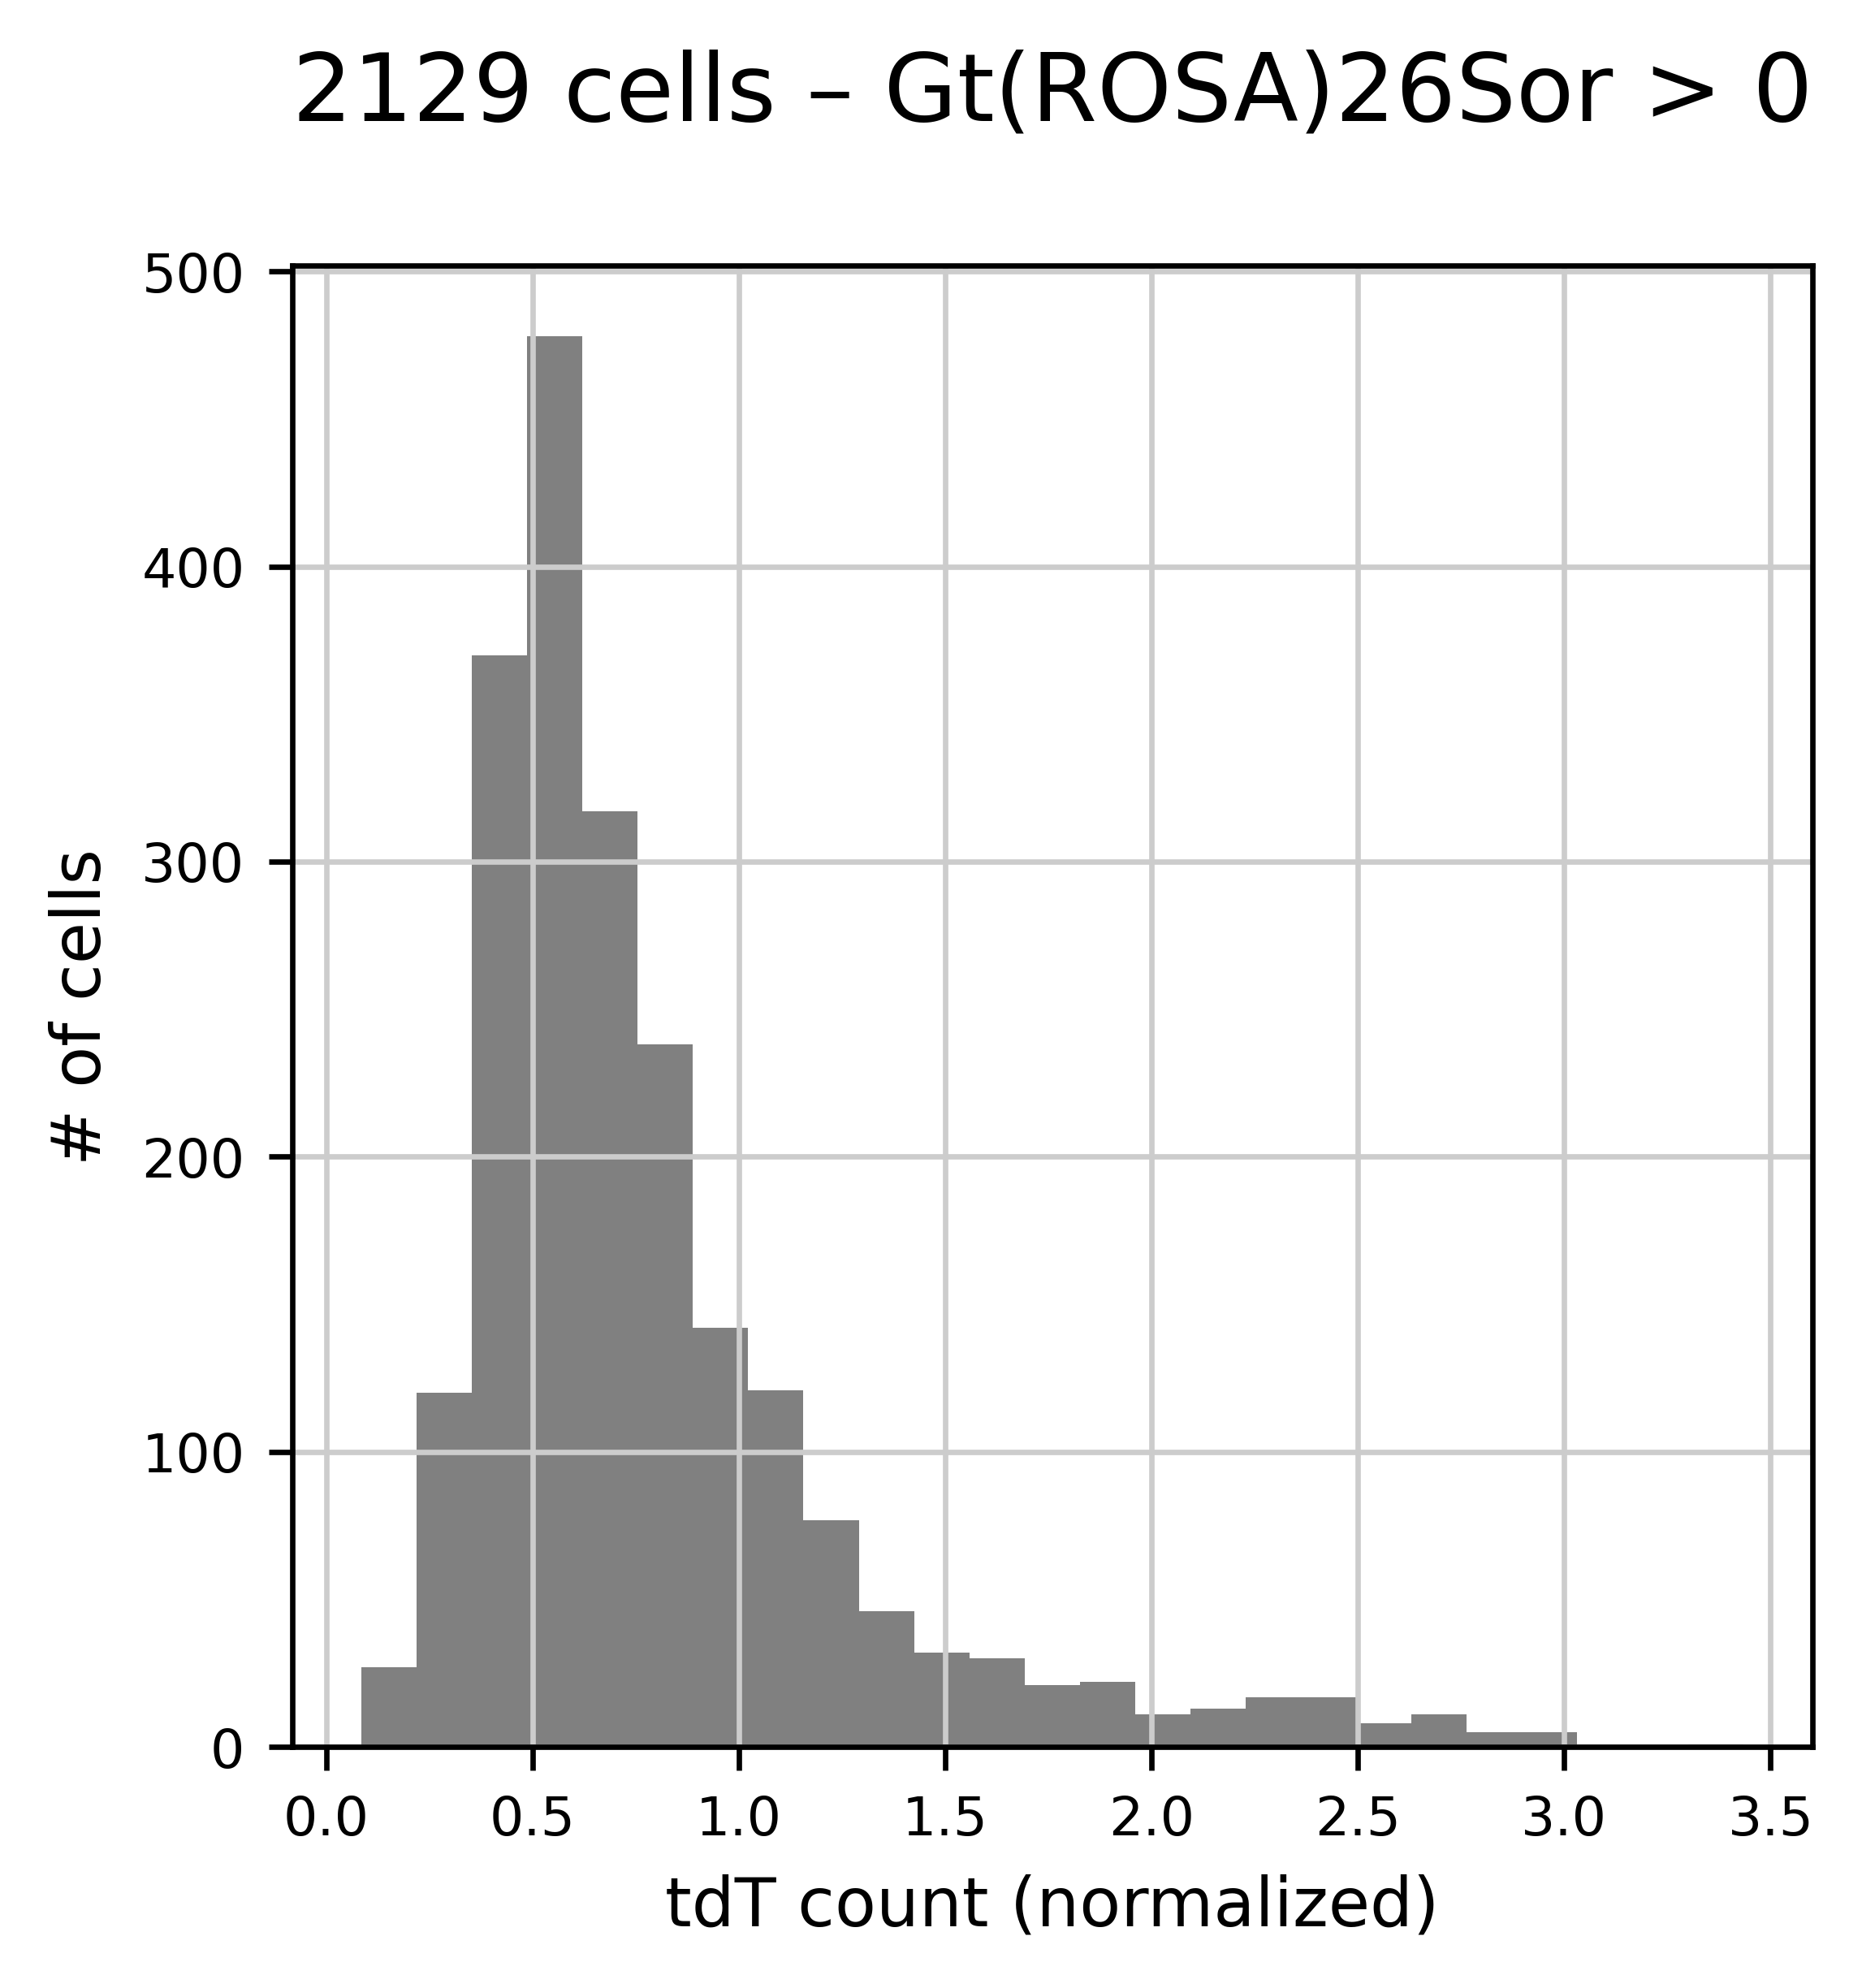

In [20]:
tdT_counts = adata.to_df()[tdT_gene]
tdT_counts = tdT_counts[tdT_counts > 0]

plt.figure(figsize=(4,4))
plt.hist(tdT_counts, color='grey',bins=25)
plt.style.use('seaborn-white')
plt.xlabel("tdT count (normalized)")
plt.ylabel("# of cells")
plt.title(f'{tdT_counts.shape[0]} cells – {tdT_gene} > 0\n',fontsize=14)
plt.savefig('figures/tdT_counts_hist.pdf',dpi = 300, bbox_inches='tight')
plt.show()

In [21]:
def bar_plot_tdT_clusters(adata,save=None):
    tdT_clusters = pd.concat([
        adata.obs['leiden'],
        adata.to_df()[tdT_gene]
    ],axis=1).groupby('leiden').mean()

    plt.figure(figsize=(12,4))
    # plt.hist(tdT_counts, color='grey',bins=25)
    # plt.style.use('seaborn-white')
    plt.xlabel("leiden clusters")
    plt.ylabel("average (tdT count)")
    # plt.title(f'{tdT_counts.shape[0]} cells – tdT>0\n')

    plt.bar(tdT_clusters.index.tolist(),tdT_clusters[tdT_gene].tolist(),color='grey')
    if save: 
        plt.savefig(f'figures/tdT_counts_{save}_leiden_hist.pdf',dpi = 300, bbox_inches='tight')
    plt.show()

/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.9/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'group' as categorical
/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.9/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'tdT' as categorical




In [22]:
sc.pl.umap(
    adata, color=['group','leiden','log1p_total_counts',tdT_gene],legend_fontsize='x-small',
    vmin=[None,None,6,-2], vmax=[None,None,9,2], cmap='bwr', layer='scaled',
    size=40, hspace=2,
    save='tdT.pdf'
    # add_outline=1
)

!mv figures/umaptdT.pdf figures/tdT_umap.pdf

## 

In [23]:
adata.shape

(23539, 32285)

In [24]:
set(adata.obs.group)

{'MDMA', 'Meth', 'Saline'}

## Meth

In [25]:
Meth = adata[adata.obs.group == 'Meth']

In [26]:
clustering(Meth)

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


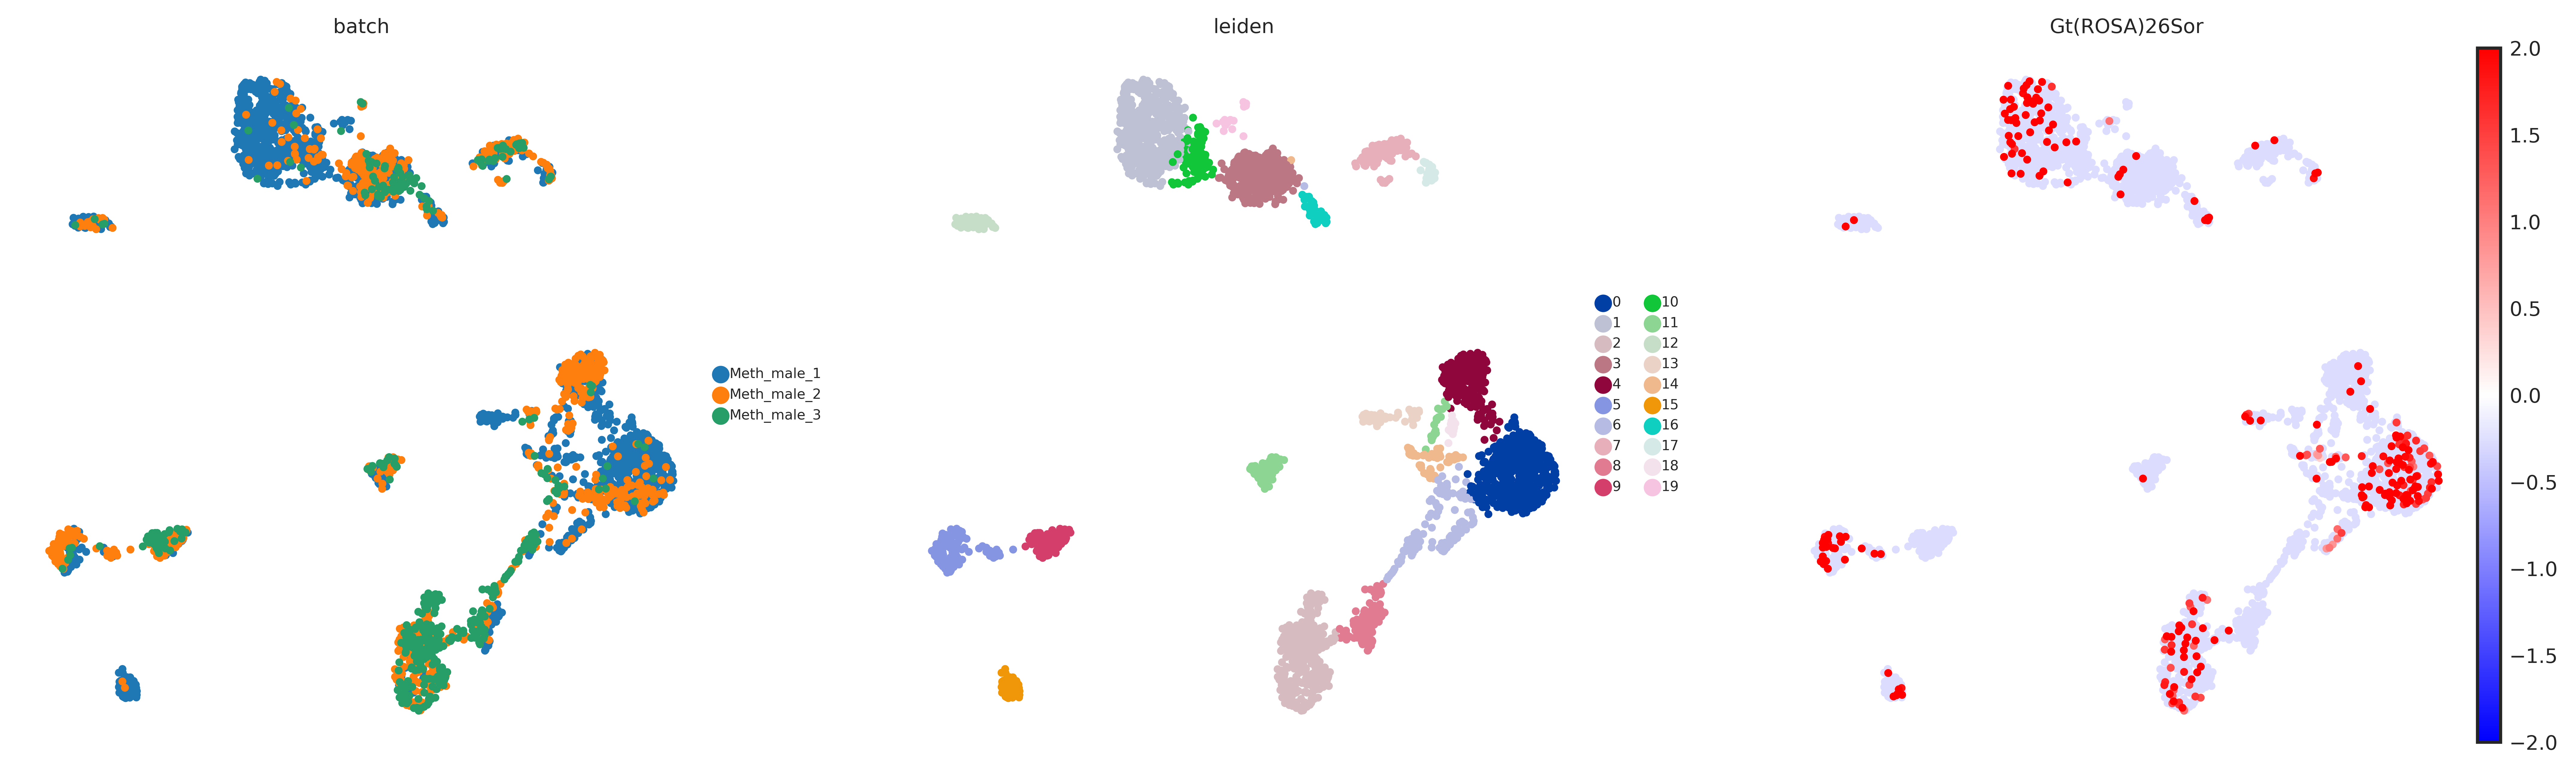

In [27]:
sc.pl.umap(
    Meth, color=['batch','leiden',tdT_gene],legend_fontsize='x-small',
    vmin=-2,vmax=2, cmap='bwr', layer='scaled',
    size=40, hspace=2,
    save='tdT.pdf'
    # add_outline=1
)

!mv figures/umaptdT.pdf figures/tdT_umap_Meth.pdf

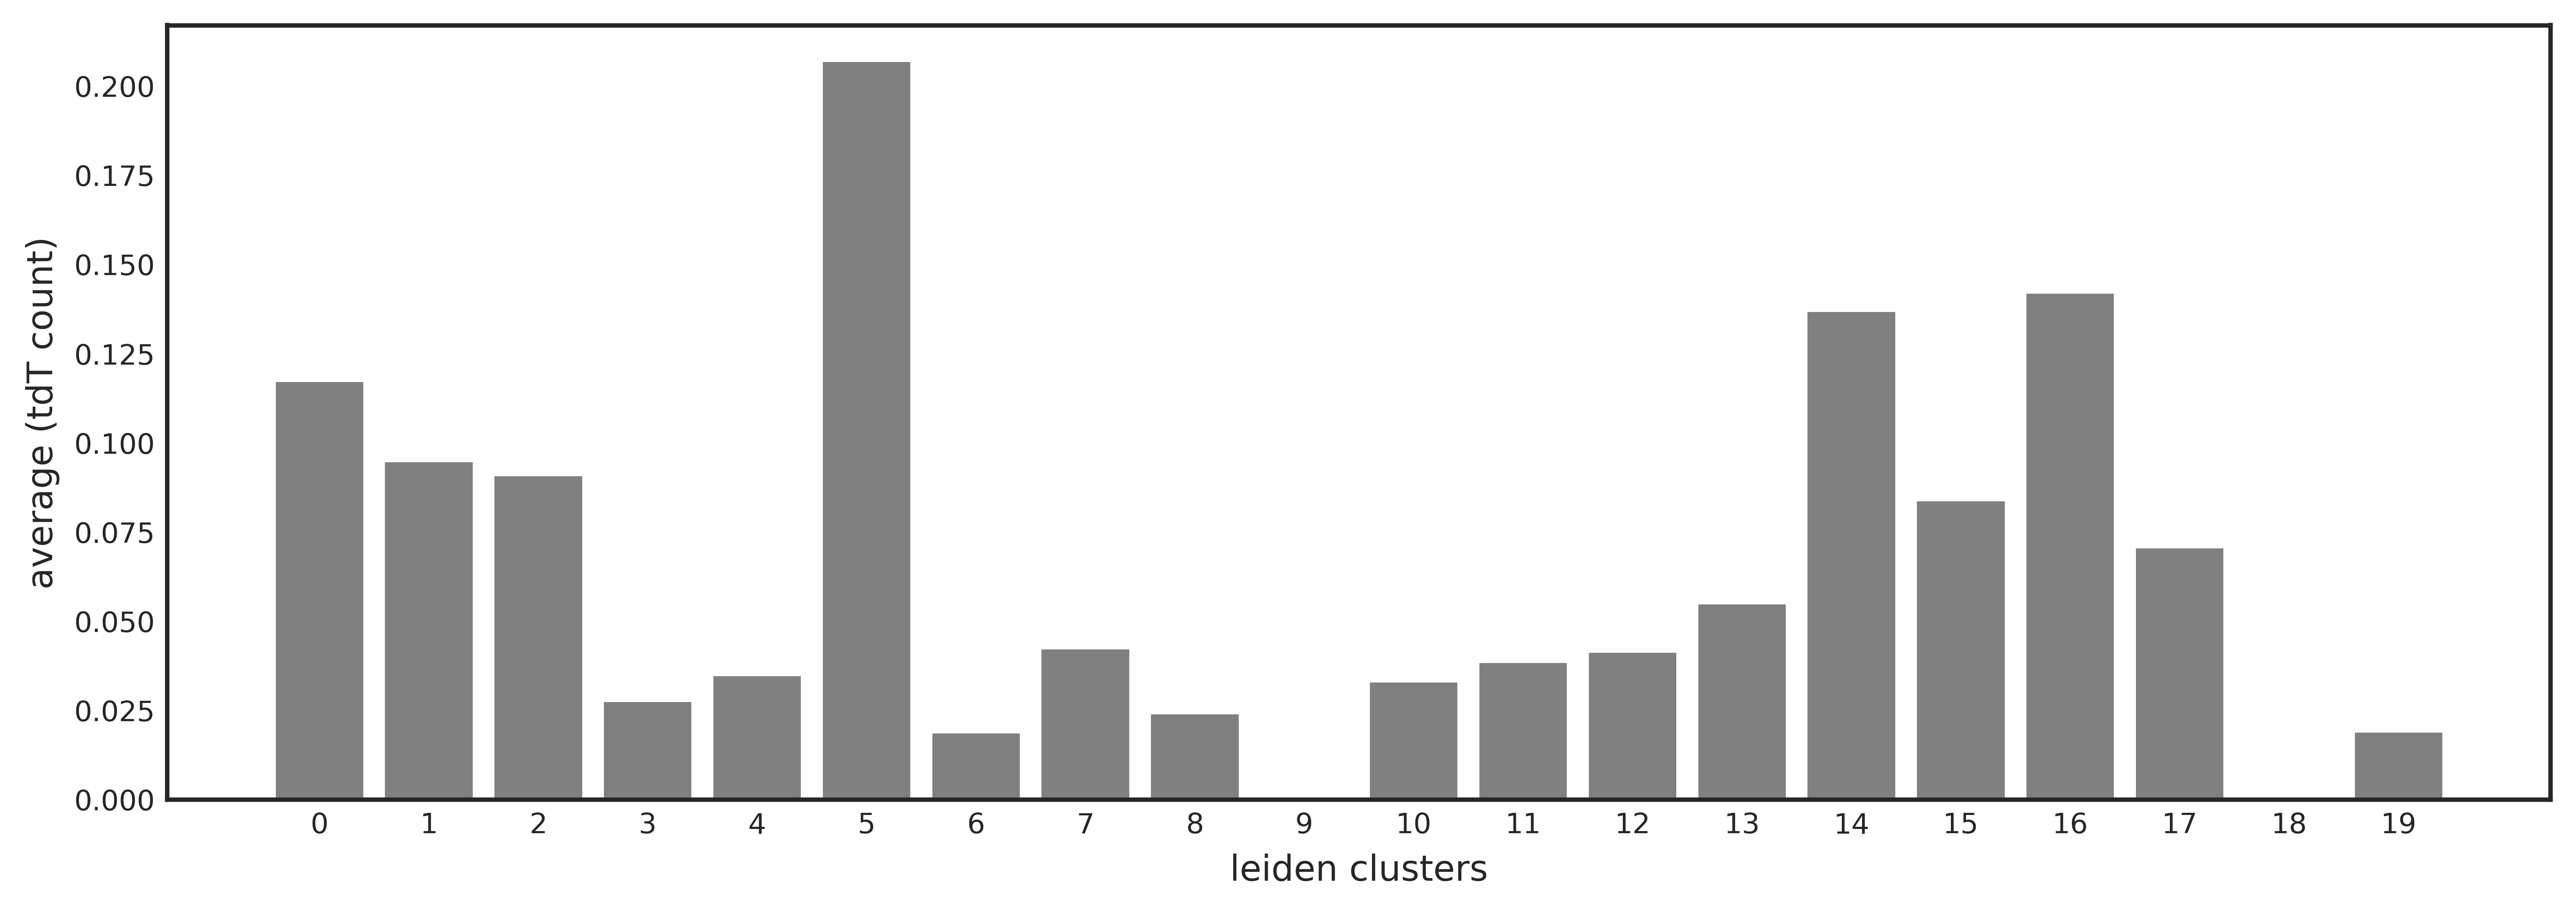

In [28]:
bar_plot_tdT_clusters(Meth,'Meth')

## MDMA

In [29]:
MDMA = adata[adata.obs.group == 'MDMA']

In [30]:
clustering(MDMA)

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


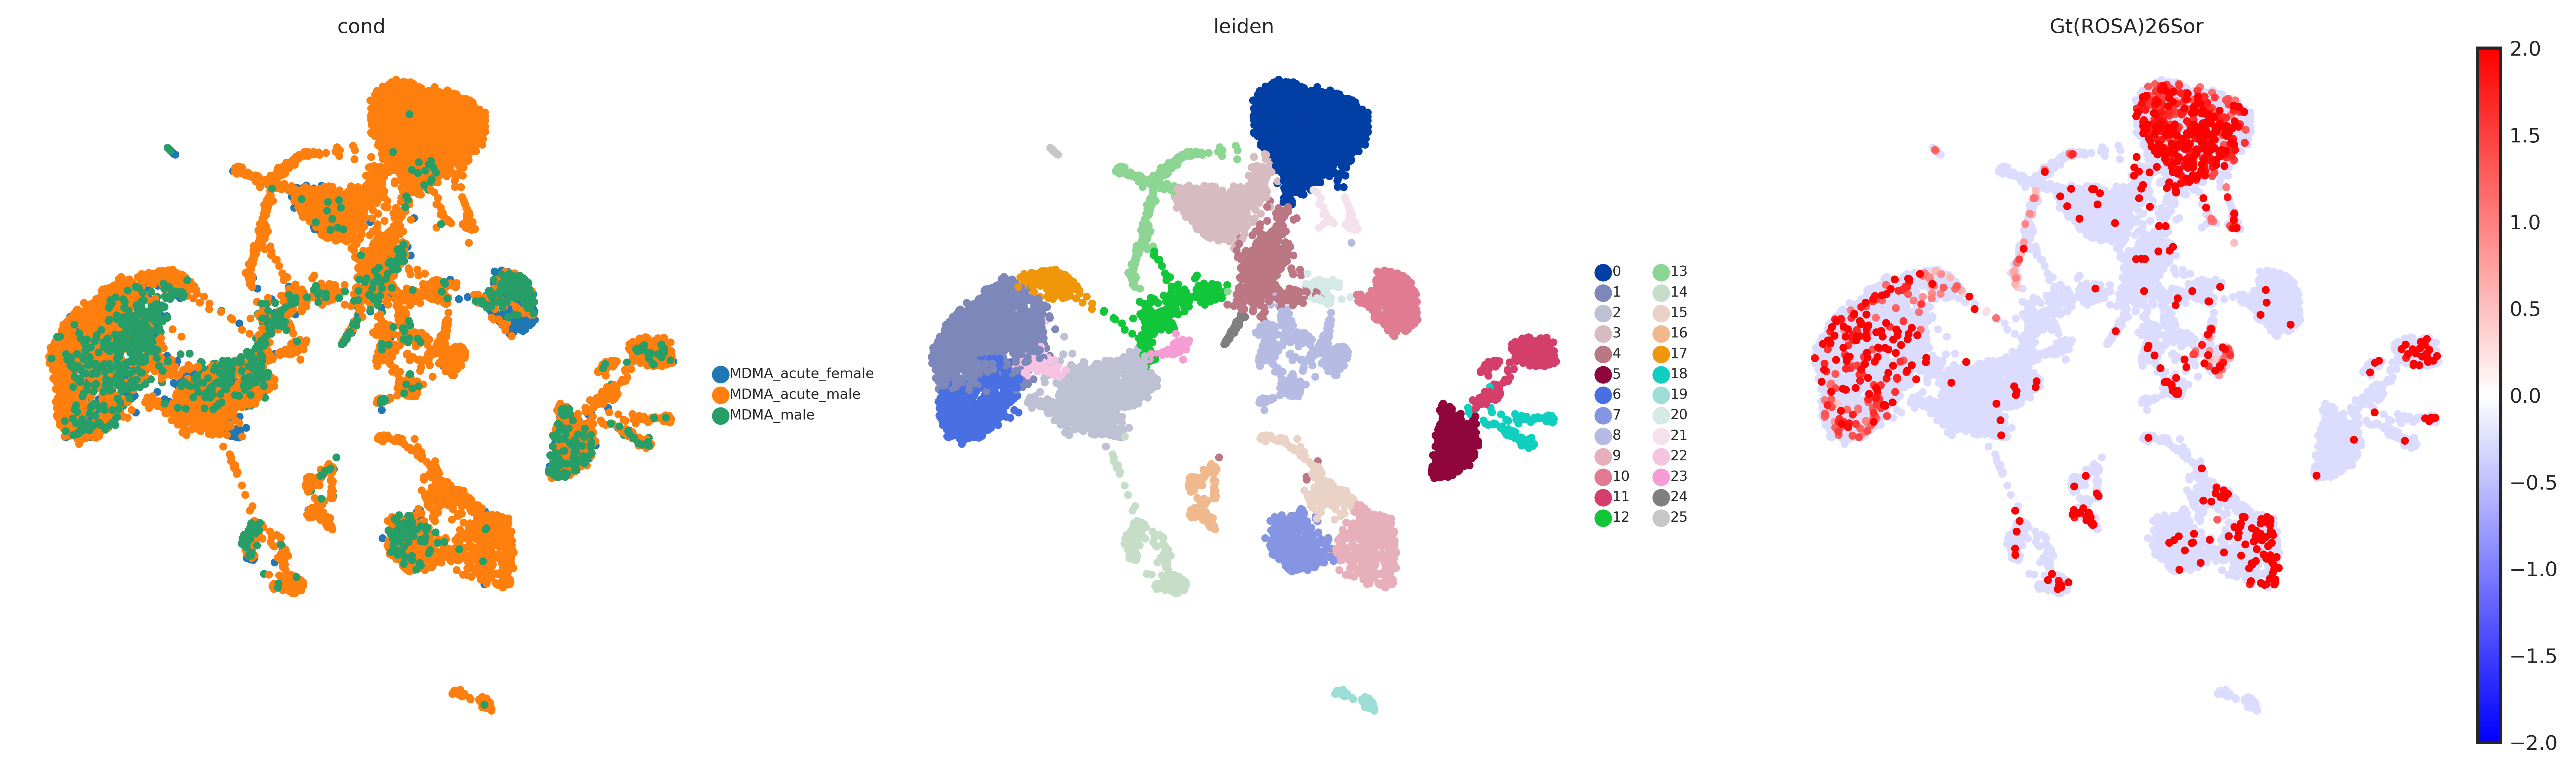

In [31]:
sc.pl.umap(
    MDMA, color=['cond','leiden',tdT_gene],legend_fontsize='x-small',
    vmin=-2,vmax=2, cmap='bwr', layer='scaled',
    size=40, hspace=2,
    save='tdT.pdf'
    # add_outline=1
)

!mv figures/umaptdT.pdf figures/tdT_umap_MDMA.pdf

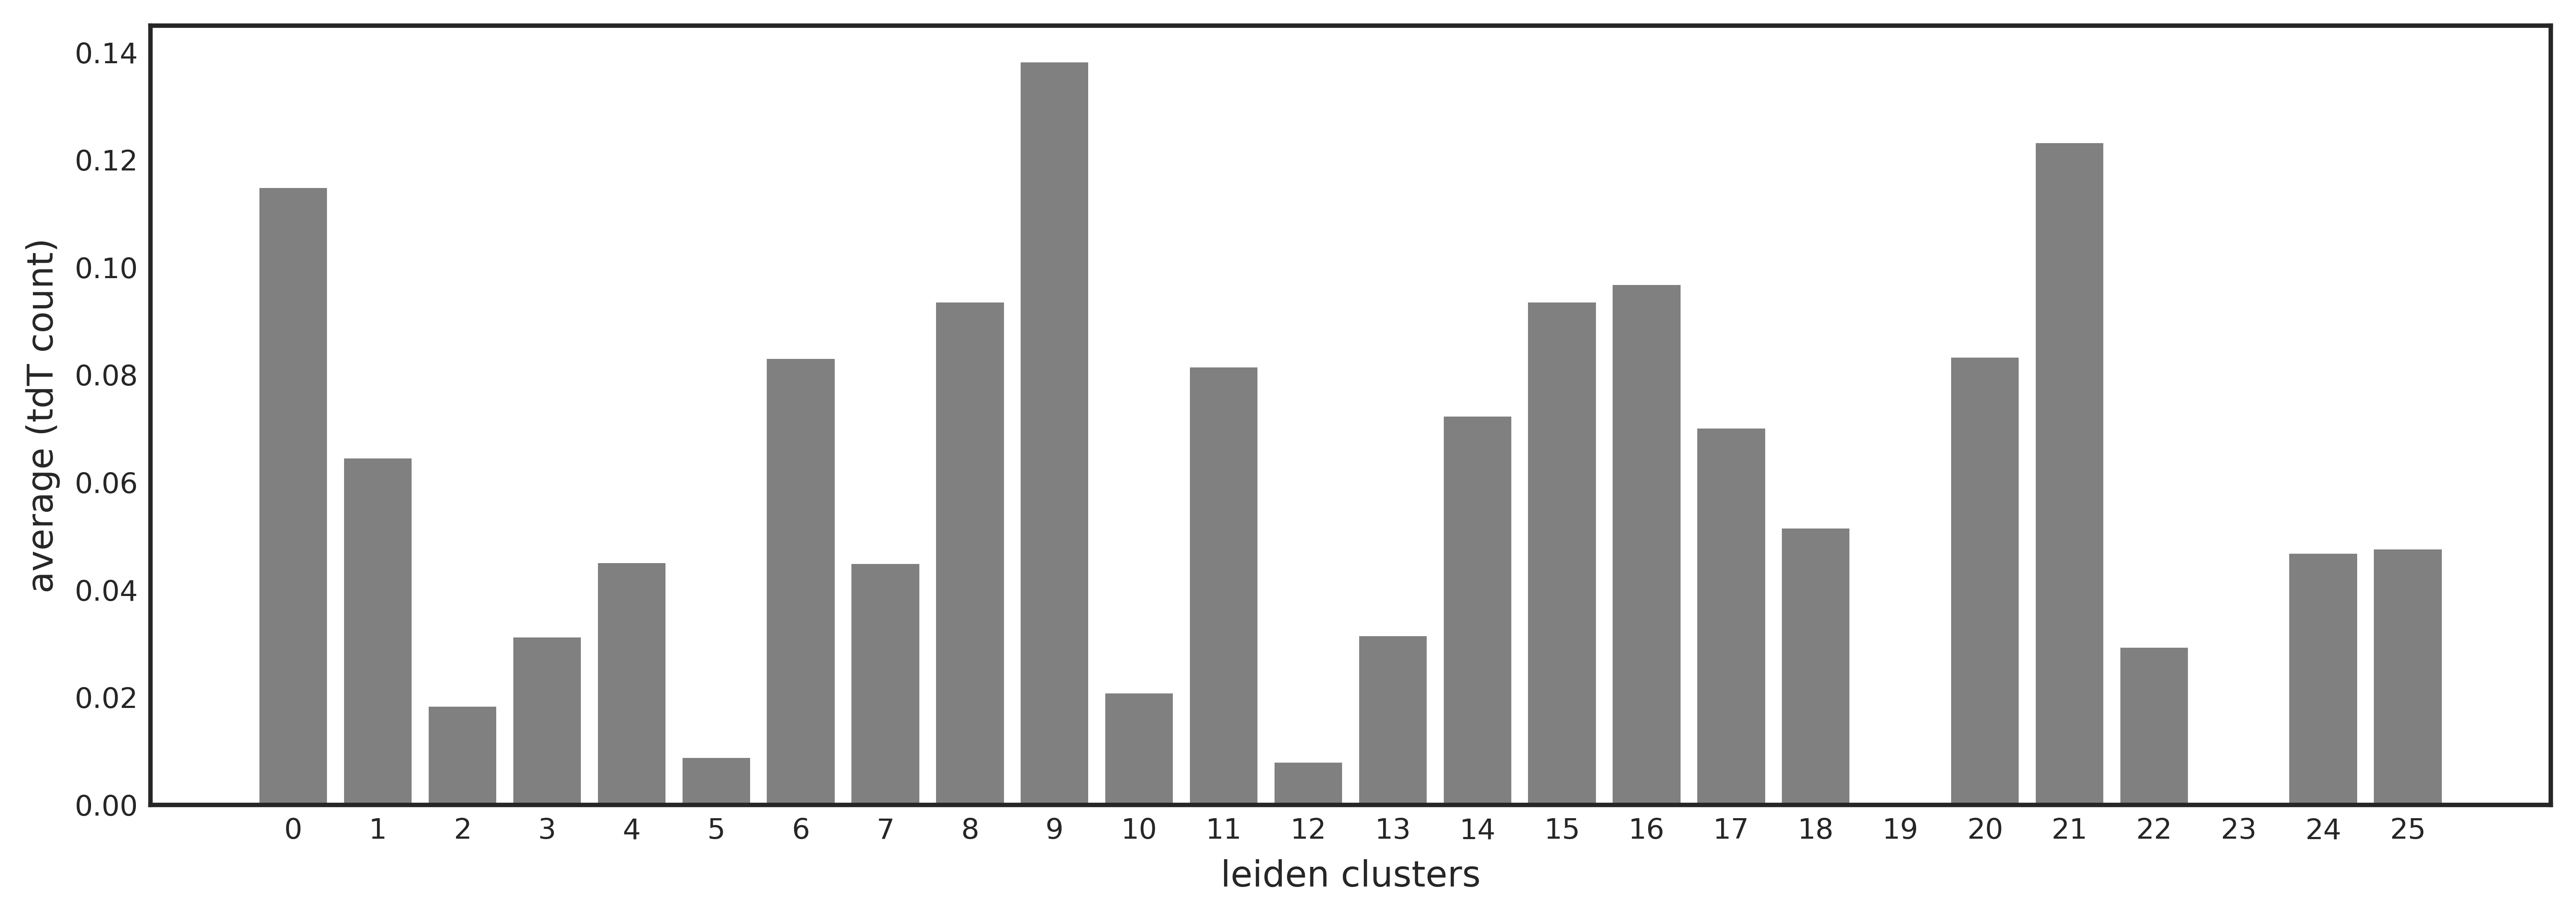

In [32]:
bar_plot_tdT_clusters(MDMA,'MDMA')

## Saline

In [33]:
Saline = adata[adata.obs.group == 'Saline']

In [34]:
clustering(Saline)

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


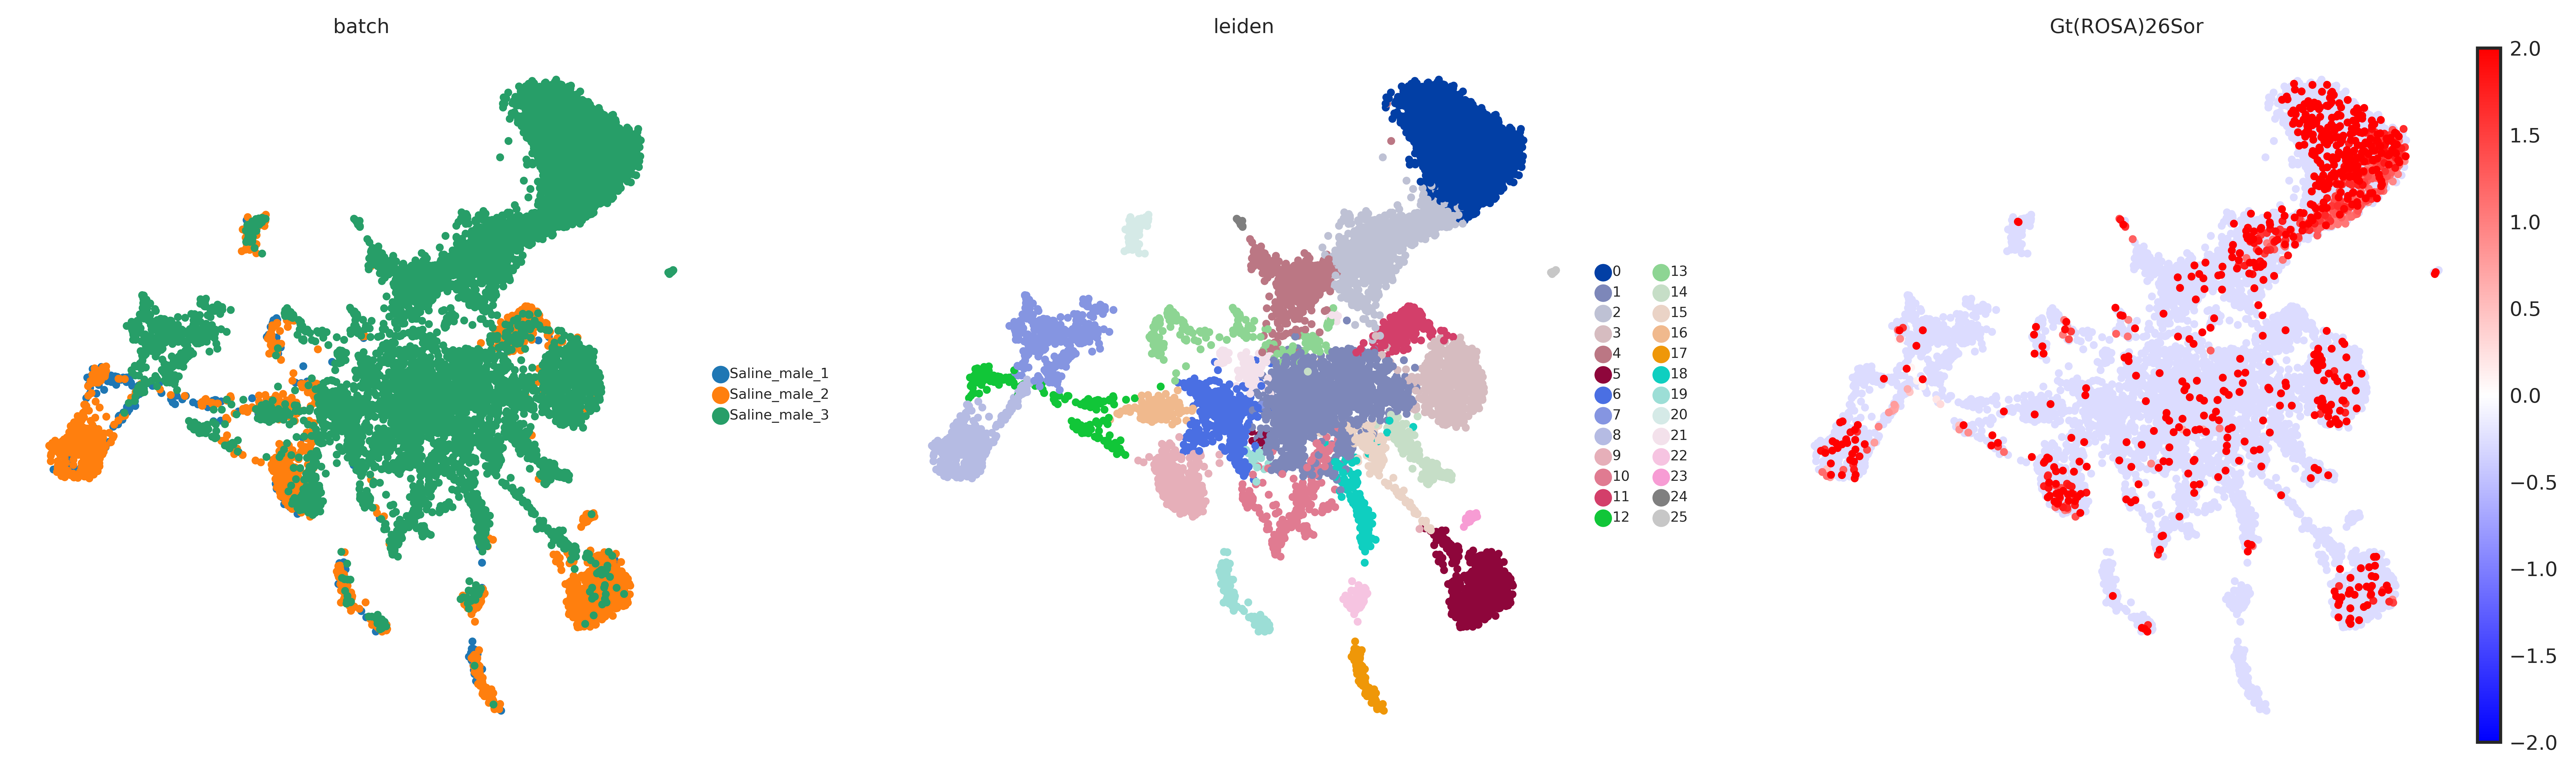

In [35]:
sc.pl.umap(
    Saline, color=['batch','leiden',tdT_gene],legend_fontsize='x-small',
    vmin=-2,vmax=2, cmap='bwr', layer='scaled',
    size=40, hspace=2,
    save='tdT.pdf'
    # add_outline=1
)

!mv figures/umaptdT.pdf figures/tdT_umap_Saline.pdf

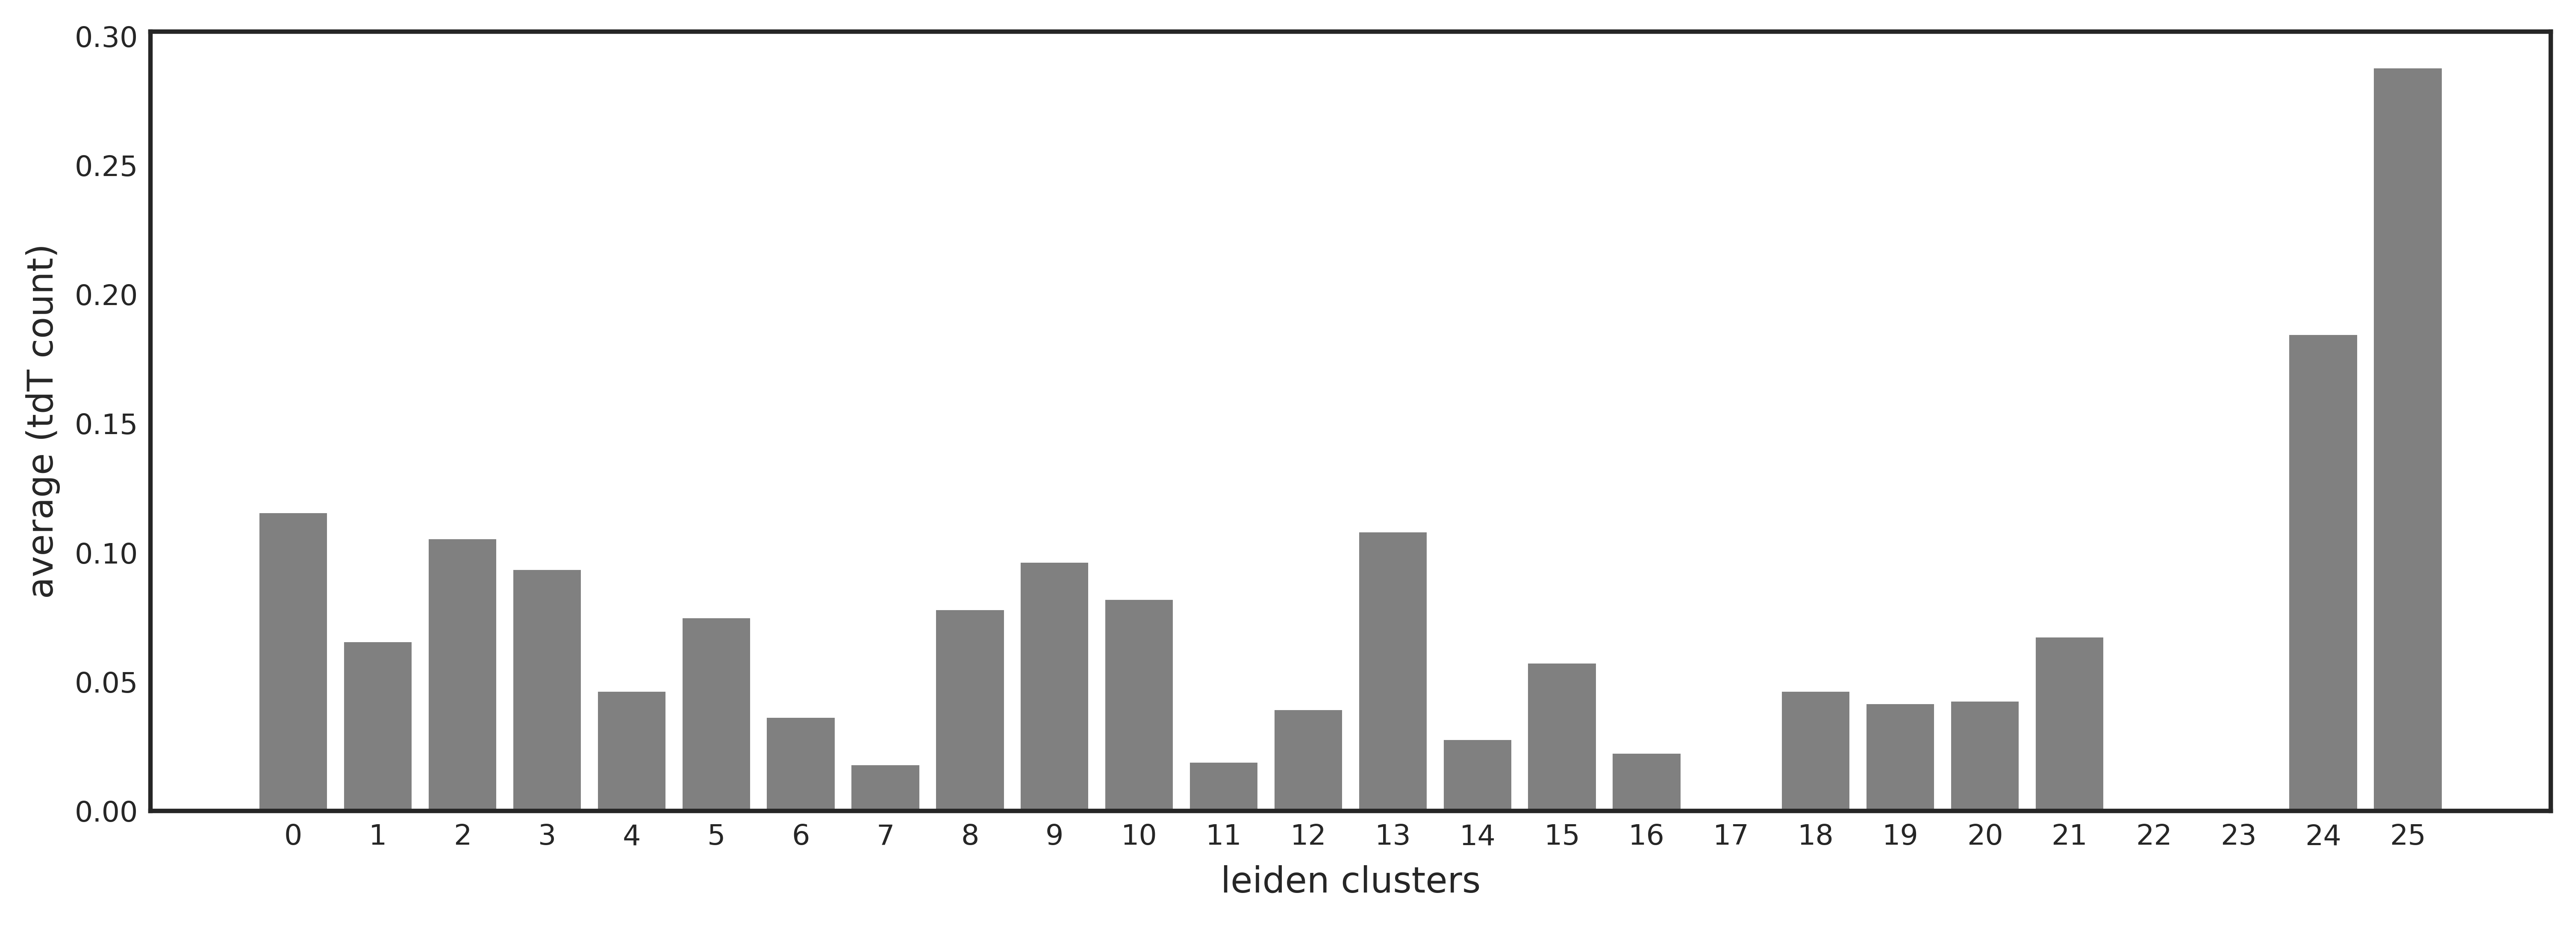

In [36]:
bar_plot_tdT_clusters(Saline,'Saline')

In [ ]:
sc.pl.rank_genes_groups_heatmap(
    pbmc, n_genes=3, use_raw=False, swap_axes=True, vmin=-3, vmax=3, cmap='bwr', layer='scaled', 
    figsize=(10,7), #show=False
)


In [28]:
# adata2 = adata_flt_dd.copy()
# sc.pp.normalize_total(adata2, target_sum=1e4)
# sc.pp.log1p(adata)
# sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
# sc.pl.highly_variable_genes(adata)
# clustering(adata2)

In [29]:
# sc.pl.umap(adata2, color='cond',save='_cond.pdf')
# sc.pl.umap(adata2, color='batch',save='_batch.pdf')
# sc.tl.rank_genes_groups(adata2, 'leiden', method='logreg')
# rank_genes_df = pd.DataFrame(adata2.uns['rank_genes_groups']['names'])

# rank_genes_df.to_excel("celltyping/rank_genes_df.xlsx",
#              sheet_name='leiden clusters')
# adata2.var_names_make_unique()

# sc.pl.violin(
#     adata2,
#     list({gene for l in rank_genes_df.head(1).values.tolist() for gene in l}), 
#     groupby='cond',save='_rank_genes_groups.png',rotation=90
# )

In [ ]:
sc.pl.rank_genes_groups(adata2, n_genes=20, sharey=False,save='.pdf')

In [ ]:
sc.pl.stacked_violin(
    adata2,
    list({gene for l in rank_genes_df.head(3).values.tolist() for gene in l}), 
    groupby='leiden',
    # title='mRNA Clusters',
    save='leiden.pdf',
    dendrogram=True
)

In [ ]:
sc.pl.stacked_violin(
    adata2,
    list({gene for l in rank_genes_df.head(3).values.tolist() for gene in l}), 
    groupby='cond',
    # title='mRNA Clusters',
    save='cond.pdf',
    dendrogram=True
)

___

In [ ]:
writer = pd.ExcelWriter('celltyping/rank_genes.xlsx', engine='xlsxwriter')

# Write each dataframe to a different worksheet.
for c in set(adata.obs['cond']):
    rank_genes_to_df(eval(c),n=50).to_excel(writer,sheet_name=c)

# Close the Pandas Excel writer and output the Excel file.
writer.save()

# 3. Integrating and Comparing Samples
- https://scanpy.readthedocs.io/en/stable/generated/scanpy.external.pp.harmony_integrate.html

> `harmony_integrate` function uses the python port of Harmony, [harmonypy](https://github.com/slowkow/harmonypy), to integrate single-cell data stored in an AnnData object. As Harmony works by **adjusting the principal components**, this function should be **run after performing PCA but before computing the neighbor graph**.

- https://scanpy.readthedocs.io/en/stable/generated/scanpy.external.pp.mnn_correct.html#scanpy.external.pp.mnn_correct


- https://github.com/JinmiaoChenLab/Batch-effect-removal-benchmarking

> Based on our results, Harmony, LIGER, and Seurat 3 are the recommended methods for batch integration. Due to its significantly shorter runtime, **Harmony** is recommended as the first method to try, with the other methods as viable alternatives.

<!-- Aidan's notes 
> The 4 strategies I will try are: 
> 1. No integration (just mergin all datasets together). This will give me a sense of the batch effect between samples
> 2. Seurat standard integration (using the anchro identification method)
> 3. Seurat scTransform (adjusts counts based on umi per cell)
> 4. Harmony

Try [harmonypy](https://anaconda.org/bioconda/harmonypy)

These are the critical R packages I used to write [this note](https://slowkow.com/notes/harmony-animation/):
- [MUDAN](https://github.com/jefworks/MUDAN) by Jean Fan
- [Harmony](https://github.com/immunogenomics/harmony) and [presto](https://github.com/immunogenomics/presto) by Ilya Korsunsky
- [gganimate](https://gganimate.com/) by Thomas Lin Pedersen -->

In [ ]:
# def clustering(adata,lognorm=False,rep=None, n_neighbor=30,res=None):
#     if lognorm: 
#         sc.pp.log1p(adata)
#     sc.pp.pca(adata)
#     sc.pp.neighbors(adata, use_rep=rep, n_neighbors=n_neighbor)   # why can't we just work with the default neighbors?
#     sc.tl.umap(adata)
#     sc.tl.leiden(adata,resolution=res)


# def join_graphs_max(g1: "sparse.spmatrix", g2: "sparse.spmatrix"):
#     """Take the maximum edge value from each graph."""
#     out = g1.copy()
#     mask = g1 < g2
#     out[mask] = g2[mask]
#     return out
#     adata.obsp["connectivities"] = join_graphs_max(adata.obsp["rna_connectivities"], adata.obsp["protein_connectivities"])
#     sc.pp.neighbors(adata, n_neighbors=30)   # why can't we just work with the default neighbors?
#     sc.tl.leiden(adata, key_added="joint_leiden")
#     sc.tl.umap(adata)


# def annotate_rna_protein(adata):
#     '''Annotate data based on mRNA expression and surface protein abundance 
#     '''
#     protein = adata[:, adata.var["feature_types"] == "Antibody Capture"].copy()
    
#     clustering(protein,lognorm=True)
    
#     protein.var.set_index('gene_ids',inplace=True)    
#     adata.obs = pd.concat([adata.obs,protein.to_df()],axis=1) 
    
#     print ('protein clustering is done!')
    
#     rna = adata[:, adata.var["feature_types"] == "Gene Expression"].copy()
#     clustering(rna,lognorm=True)

#     print ('RNA clustering is done!')

#     odata = rna.copy()
    
#     odata.obsm["protein_umap"] = protein.obsm["X_umap"]
#     odata.obs["protein_leiden"] = protein.obs["leiden"]
#     odata.obsp["protein_connectivities"] = protein.obsp["connectivities"].copy()

#     odata.obsm["rna_umap"] = rna.obsm["X_umap"]
#     del odata.obs["leiden"]
#     odata.obs["rna_leiden"] = rna.obs["leiden"]
#     odata.obsp["rna_connectivities"] = rna.obsp["connectivities"].copy()
    
#     return odata

In [ ]:
def umap_totalVI(adata,ax=None):
    """Now we can compute clusters and visualize the latent space.
    """
    sc.pp.neighbors(adata, use_rep="X_totalVI")
    sc.tl.umap(adata, min_dist=0.4)
    sc.tl.leiden(adata, key_added="leiden_totalVI")

    sc.pl.umap(
        adata, 
        color=[
#             "leiden_totalVI", 
            "batch"
        ], 
        frameon=False,ncols=1,ax=ax
    )

In [ ]:
def make_pro_adata(adata):
    """Visualize denoised protein values
    To visualize protein values on the umap, we make a temporary protein adata object.
    We have to copy over the umap from the original adata object.
    """
    pro_adata = sc.AnnData(adata.obsm["protein_expression"].copy(), obs=adata.obs)
    sc.pp.log1p(pro_adata)
    # Keep log normalized data in raw
    pro_adata.raw = pro_adata
    pro_adata.X = adata.obsm["denoised_protein"]

    pro_adata.obsm["X_umap"] = adata.obsm["X_umap"]
    pro_adata.obsm["X_totalVI"] = adata.obsm["X_totalVI"]

    # from .obsm -> .obs
    names = adata.obsm["protein_foreground_prob"].columns
    for p in names:
        pro_adata.obs["{}_fore_prob".format(p)] = adata.obsm["protein_foreground_prob"].loc[:, p]
    return pro_adata

def umap_pro_totalVI(adata,sample=''):
    ### Visualize denoised protein values
    # plot umap
    fig1 = sc.pl.umap(
        pro_adata, 
        color=pro_adata.var_names,
        ncols=3, 
        vmax="p99",
        use_raw=False,
        frameon=False,
        return_fig=True,
        wspace=0.1
    )
    fig1.suptitle(f'{sample}\ndenoised protein values\n{str(adata.shape[0])} cells')
    
    ### Visualize probability of foreground
    fig2 = sc.pl.umap(
        pro_adata,
        color=["{}_fore_prob".format(p) for p in pro_adata.var_names],
        ncols=3,
        color_map="cividis",
        frameon=False,
        wspace=0.1,
        return_fig=True
    )
    fig2.suptitle('probability of foreground')
    return fig1,fig2

> Here we visualize the probability of foreground for each protein and cell (projected on UMAP).
Some proteins are easier to disentangle than others. Some proteins end up being "all background".
For example, CD15 does not appear to be captured well, when looking at the denoised values above we see little localization in the monocytes.

> __Note__: 
>> While the foreground probability could theoretically be used to identify cell populations, we recommend using the denoised protein expression, which accounts for the foreground/background probability, but preserves the dynamic range of the protein measurements. Consequently, the denoised values are on the same scale as the raw data and it may be desirable to take a transformation like log or square root.
> By viewing the foreground probability, we can get a feel for the types of cells in our dataset. For example, it's very easy to see a population of monocytes based on the CD14 foregroud probability.


In [ ]:
%%time 
fig, axes = plt.subplots(nrows=3, ncols=1,figsize=(5,10),dpi=300)
i = 0
for cond, adata in data_denoised.items():
    umap_totalVI(adata,axes[i])
    axes[i].set_title(cond)
    i+=1

fig.suptitle('totalVI denoised RNA data')
fig.tight_layout()
fig.savefig('figures/totalVI_RNA_umap.pdf')

In [ ]:
%%time 
for cond, adata in data_denoised.items():
    print ('\033[1m' + cond)
    pdf_pages = PdfPages(f'figures/totalVI_Protein_umap_{cond}.pdf')
    # The PDF document
    # Create a figure instance (ie. a new page)
    fig1 = plot.figure(dpi=300)
    fig2 = plot.figure(dpi=300)
    # Plot whatever you wish to plot
    pro_adata=make_pro_adata(adata)
    fig1,fig2 = umap_pro_totalVI(pro_adata,cond)
    # Done with the page
    fig1.set_size_inches(18.5, 10.5)
    pdf_pages.savefig(fig1)
    plt.close(fig1)    
    fig2.set_size_inches(18.5, 10.5)
    pdf_pages.savefig(fig2)
    plt.close(fig2)
    # Write the PDF document to the disk
    pdf_pages.close()

___

Save each sample into a `h5ad` file.

In [ ]:
# data = {}

for cond in data_denoised:
    print (cond)

    # adata = ad.AnnData(
    #     # denoised rna counts
    #     X=pd.DataFrame(
    #         data   = data_denoised[cond].layers['denoised_rna'],
    #         index  = data_denoised[cond].obs.index,
    #         columns= data_denoised[cond].var.index
    #     ),
    #     # batch + denoised protein counts
    #     obs=pd.concat([
    #         data_denoised[cond].obs['batch'],
    #         data_denoised[cond].obsm['denoised_protein'],
    #     ],axis=1)
    # )
    
    adata = data_denoised[cond].copy()
    
    # Save `adata`s to file
    adata.write(f'preprocessing/{cond}-denoised.h5ad.gz',compression='gzip')
    
    # data[cond] = adata
    
    del adata

In [ ]:
# data_denoised['NSG'].obsm['denoised_protein']

In [ ]:
# umap_totalVI(data_denoised['NSG'],None)

### Differential expression

> Here we do a one-vs-all DE test, where each cluster is tested against all cells not in that cluster. The results for each of the one-vs-all tests is concatenated into one DataFrame object. Inividual tests can be sliced using the "comparison" column. Genes and proteins are included in the same DataFrame.

> __Important__
>> We do not recommend using totalVI denoised values in other differential expression tools, as denoised values are a summary of a random quantity. The totalVI DE test takes into account the full uncertainty of the denoised quantities.

In [ ]:
# de_df = vae.differential_expression(
#         groupby="leiden_totalVI", 
#         delta=0.5,
#         batch_correction=True
# )
# de_df.head(5)

> Now we filter the results such that we retain features above a certain Bayes factor (which here is on the natural log scale) and genes with greater than 10% non-zero entries in the cluster of interest.

In [ ]:
%%time 
data = {}

for file in glob('preprocessing/*[1-2]*h5ad.gz'):
    
    sample = file.split('/')[1].replace('.h5ad.gz','')
    print (sample)
    
    data[sample] = sc.read_h5ad(file)
    
    data[sample].obs = data[sample].obs.set_index(
        data[sample].obs.index.astype(str) + '_' + sample
    )

Merge `adata` objects 

In [ ]:
%%time 
mergedadata = ad.concat(dict([(sample, data[sample]) for sample in data]), label="batch")
mergedadata.obsm = None

for col in ['protein_leiden','n_genes_by_counts','total_counts','total_counts_mt','pct_counts_mt','rna_leiden','doublet_score','predicted_doublet']:
    del mergedadata.obs[col]

cite_cols = mergedadata.obs.columns[:-1] 
cite_cols += '_protein'
mergedadata.obs.columns = list(cite_cols) + ['batch']

In [ ]:
mergedadata0 = mergedadata.copy()

### harmony

In [ ]:
# sc.pp.neighbors(mergedadata0, use_rep='X_pca')
# sc.tl.umap(mergedadata0)
# sc.tl.leiden(mergedadata0)

In [ ]:
# sc.tl.pca(mergedadata)
# sce.pp.harmony_integrate(mergedadata, 'batch')
# sc.pp.neighbors(mergedadata, use_rep='X_pca_harmony')
# sc.pp.neighbors(mergedadata, use_rep='X_pca')
# sc.tl.umap(mergedadata)
# sc.tl.leiden(mergedadata)

compare 

In [ ]:
# fig, (ax1,ax2) = plt.subplots(1,2,figsize=(10, 5), dpi=300)
# # fig.subplots_adjust(top = 1, bottom = 0, right = 1, left = 0, hspace = 1, wspace = 1)

# sc.pl.embedding(mergedadata0, basis='umap',color='batch', title='raw',size=5,ax=ax1,show=False,legend_loc=False)
# sc.pl.embedding(mergedadata, basis='umap',color='batch', title='harmony',size=5,ax=ax2,show=False)
# fig.tight_layout()
# plt.savefig('figures/umap_compare.pdf')

protein 

In [ ]:
# sc.pl.embedding(mergedadata, basis='umap',color=mergedadata.obs.columns, size=2,vmin=2,vmax=8,save='_harmony.pdf')

### UMAP

In [ ]:
sc.tl.pca(mergedadata)#,svd_solver="lobpcg")

In [ ]:
sc.pp.neighbors(mergedadata, use_rep='X_pca')
sc.tl.umap(mergedadata)
sc.tl.leiden(mergedadata)

In [ ]:
mergedadata

In [ ]:
sc.pl.embedding(
    mergedadata, basis='umap', color=['CD3_protein', 'Cd3e','batch','leiden'], size=10,
    # save='_T_cells.pdf'
)

sc.pl.embedding(
    mergedadata[[clst in ['6','24'] for clst in mergedadata.obs.leiden]], 
    basis='umap',
    color=[
        'CD3_protein', 'Cd3e',
        # 'CD8a_protein', 'Cd8a',
        # 'CD4_protein', 'Cd4',
        # 'CD14_protein', 'Cd14',
        # 'CD19_protein', 'Cd19','Ms4a1',
        # 'CD11c_protein', 'Itgax',
        'batch',
        'leiden'
    ],
    size=10,
#     vmin=0,
#     vmax=3,
    # save='_T_cells.pdf'
)


In [ ]:
T_cells = mergedadata[[clst in ['6','24'] for clst in mergedadata.obs.leiden]].copy()

In [ ]:
T_cells.write('preprocessing/T_cells.h5ad.gz',compression='gzip')

In [ ]:
NonImmuneadata = mergedadata[mergedadata.obs.CD45_protein <= 6].copy()

In [ ]:
# clustering(NonImmuneadata)

In [ ]:
sc.pl.embedding(NonImmuneadata, basis='umap',
                color=[
                    'Epcam', # —> epithelial cells
                    'Pecam1',# —> Endothelial cells
                    'Fbln1', # —> fibroblasts
                    'batch',
                    'leiden'
                ],
                size=10,
#                 vmin=2,vmax=5,
                save='_NonImmune.pdf')

In [ ]:
CD45adata = mergedadata[mergedadata.obs.CD45_protein > 6].copy()

In [ ]:
# clustering(CD45adata)

In [ ]:
sc.pl.embedding(
    CD45adata, basis='umap',
    color=[
        'Epcam', # —> epithelial cells
        'Pecam1',# —> Endothelial cells
        'Fbln1', # —> fibroblasts
                    
        'CD3_protein', 'Cd3e',
        'CD8a_protein', 'Cd8a',
        'CD4_protein', 'Cd4',
        'CD14_protein', 'Cd14',
        'CD19_protein', 'Cd19','Ms4a1',
        'CD11c_protein', 'Itgax',

        'batch',
        'leiden'
    ],
#                 size=2,vmin=3,
#                 vmax=5
    save='_CD45+.pdf'
)

In [ ]:
# clustering(mergedadata,lognorm=False,n_neighbor=10,res=1)

In [ ]:
# sc.pl.embedding(mergedadata, basis='umap',color=mergedadata.obs.columns, size=2,vmin=2,vmax=8)#,save='_harmony.pdf')

In [ ]:
# %%time 
# pdf_pages = PdfPages('figures/umap.pdf')

# # The PDF document
# for sample in data:
#     adata = data[sample].copy()

#     # Create a figure instance (ie. a new page)
#     fig = plot.figure(dpi=300)

#     # Plot whatever you wish to plot
#     print ('\033[1m' + sample)
#     fig = sc.pl.embedding(adata, basis='rna_umap',color=adata.obs.columns[2:], size=10,show=False,return_fig=True)
#     fig.suptitle(sample +'\n'+str(adata.shape[0])+' cells, '+str(adata.shape[1])+' genes', fontsize=20)
    
#     fig.set_size_inches(18.5, 10.5) # https://stackoverflow.com/questions/332289/how-do-you-change-the-size-of-figures-drawn-with-matplotlib
    
#     # Done with the page
#     pdf_pages.savefig(fig)
#     plt.close(fig)    
# #     del adata
    
# # Write the PDF document to the disk
# pdf_pages.close()

## 4. Huge heatmap!

In [ ]:
# clustering(mergedadata,lognorm=False,n_neighbor=10,res=1)

In [ ]:
mergedadata.obs.columns#[:-2]

In [ ]:
sc.pl.heatmap(mergedadata, mergedadata.obs.columns[:-2], groupby='leiden', dendrogram=True,save='.pdf',figsize=(5,30),show=False)

In [ ]:
# # The PDF document
pdf_pages = PdfPages('figures/violin_cite.pdf')

for cite in mergedadata.obs.columns[:-2]:
    # Create a figure instance (ie. a new page)
    fig = plot.figure(figsize=(12, 6), dpi=100)

    # Plot whatever you wish to plot
    print ('\033[1m' + cite)
    ax = plt.subplot()
    sc.pl.violin(mergedadata, cite, groupby='leiden',stripplot=False,ax=ax,rotation=90,show=False)
    # Done with the page
    pdf_pages.savefig(fig)
    
# Write the PDF document to the disk
pdf_pages.close()

In [ ]:
sc.pl.stacked_violin(
    mergedadata,
    mergedadata.obs.columns[:-2],
    groupby='leiden',
    title='mRNA Clusters',
    save='mRNA.pdf',
    dendrogram=True
)

In [ ]:
# find gene markers in the 'dataset' group.
sc.tl.rank_genes_groups(mergedadata, 'leiden', method='wilcoxon', n_genes=25)

In [ ]:
sc.pl.rank_genes_groups_heatmap(mergedadata, n_genes=3, use_raw=False, vmin=-3, vmax=3, show_gene_labels=True,cmap='bwr',save='_rank_genes_groups_leiden.pdf',figsize=(30,60),show=False)

In [ ]:
mergedadata.write('preprocessing/mergedadata.h5ad.gz',compression='gzip')

In [ ]:
!conda env export --from-history

In [ ]:
# import altair as alt
# from functools import partial

# alt.renderers.enable("png")
# alt.data_transformers.disable_max_rows()

# def embedding_chart(df: pd.DataFrame, coord_pat: str, *, size=5) -> alt.Chart:
#     """Make schema for coordinates, like sc.pl.embedding."""
#     x, y = df.columns[df.columns.str.contains(coord_pat)]
#     return (
#         alt.Chart(plotdf, height=300, width=300)
#         .mark_circle(size=size)
#         .encode(
#             x=alt.X(x, axis=None),
#             y=alt.Y(y, axis=None),
#         )
#     )

# def umap_chart(df: pd.DataFrame, **kwargs) -> alt.Chart:
#     """Like sc.pl.umap, but just the coordinates."""
#     return embedding_chart(df, "umap", **kwargs)

# def encode_color(c: alt.Chart, col: str, *, qdomain=(0, 1), scheme: str = "lightgreyred") -> alt.Chart:
#     """Add colors to an embedding plot schema."""
#     base = c.properties(title=col)
#     if pd.api.types.is_categorical(c.data[col]):
#         return base.encode(color=col)
#     else:
#         return base.encode(
#             color=alt.Color(
#                 col,
#                 scale=alt.Scale(
#                     scheme=scheme,
#                     clamp=True,
#                     domain=list(c.data[col].quantile(qdomain)),
#                     nice=True,
#                 )
#             )
#         )
#     plotdf = sc.get.obs_df(
#         rna,
#         obsm_keys=[("X_umap", i) for i in range(2)] + [("protein", i) for i in rna.obsm["protein"].columns]
#     )

#     fig = (
#         alt.concat(
#             *map(partial(encode_color, umap_chart(plotdf), qdomain=(0, .95)), plotdf.columns[3:]),
#             columns=2
#         )
#         .resolve_scale(color='independent')
#         .configure_axis(grid=True)
#     )

In [ ]:
# def preprocessing(adata):
#     # Basic filtering:
#     sc.pp.filter_genes(adata, min_cells=10)
#     sc.pp.filter_cells(adata, min_genes=150)
#     # annotate the group of mitochondrial genes as 'mt'
#     adata.var['mt'] = adata.var.index.str.startswith('MT-')  
#     # Remove cells that have too many mitochondrial genes expressed or too many total counts:
#     sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)
#     adata = adata[adata.obs.n_genes_by_counts < 2500, :]
#     adata = adata[adata.obs.pct_counts_mt < 5, :]
#     # Total-count normalize (library-size correct) the data matrix 
#     # 𝐗 to 10,000 reads per cell, so that counts become comparable among cells.
#     sc.pp.normalize_per_cell(adata)
#     # Logarithmize the data:
#     sc.pp.log1p(adata)
#     # Identify highly-variable genes.
#     sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
#     adata.raw = adata
#     # Actually do the filtering
#     adata = adata[:, adata.var.highly_variable]
#     # Regress out effects of total counts per cell and the percentage of mitochondrial genes expressed. 
#     # Scale the data to unit variance.
#     sc.pp.regress_out(adata, ['total_counts', 'pct_counts_mt'])
#     # Scale each gene to unit variance. Clip values exceeding standard deviation 10.
#     sc.pp.scale(adata, max_value=10)